<a href="https://colab.research.google.com/github/Vaibhavv1525/fraud-analytics-portfolio/blob/main/01_fraud_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Data Scientist/Fraud Project /creditcard.csv')

In [4]:
# Check total dimensions of the DataFrame (rows and columns count)
df.shape

(284807, 31)

In [5]:
# Display the first 5 rows to inspect initial feature structures (PCA features V1-V28, Amount, Class)
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
# Display technical summary including data types, non-null counts, and memory consumption
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
# List all available column names in the dataset
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [8]:
# Count the frequency of each class in the target variable ('Class': 0 for normal, 1 for fraud)
df['Class'].value_counts()

,count
Class,
0,284315
1,492


In [9]:
# Calculate the percentage distribution to highlight the extreme class imbalance (~0.17% fraud rate)
df['Class'].value_counts(normalize = True)*100

,proportion
Class,
0,99.827251
1,0.172749


In [10]:
# Find the maximum value in the 'Time' column to determine the total duration covered (~48 hours)
df['Time'].max()

172792.0

## FEATURE ENGINEERING:
Convert absolute seconds into a 24-hour cyclical format (0 to 23)

In [11]:
# (Time // 3600) converts elapsed seconds to hours, and % 24 wraps the counter within a single day cycle
df['Hour'] = (df['Time'] // 3600) % 24

In [12]:
# Verify the maximum value of the engineered 'Hour' column to ensure it caps at 23.0
df['Hour'].max()

23.0

In [13]:
# Preview the last 5 rows focusing specifically on raw 'Time' and engineered 'Hour' columns
df[['Time','Hour']].tail()

,Time,Hour
284802,172786.0,23.0
284803,172787.0,23.0
284804,172788.0,23.0
284805,172788.0,23.0
284806,172792.0,23.0


In [14]:
hourly = df.groupby('Hour')['Class'].agg(['count', 'sum', 'mean'])
hourly

,count,sum,mean
Hour,,,
0.0,7695,6,0.000780
1.0,4220,10,0.002370
2.0,3328,57,0.017127
3.0,3492,17,0.004868
4.0,2209,23,0.010412
5.0,2990,11,0.003679
6.0,4101,9,0.002195
7.0,7243,23,0.003175
8.0,10276,9,0.000876


In [16]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [17]:
df['Amount'].max()

25691.16

In [18]:
df['Amount'].describe()

,Amount
count,284807.000000
mean,88.349619
std,250.120109
min,0.000000
25%,5.600000
50%,22.000000
75%,77.165000
max,25691.160000


In [19]:
df[(df['Class'] == 1) & (df['Amount'] > 500)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour
623,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1,0.0
6971,9064.0,-3.499108,0.258555,-4.489558,4.853894,-6.974522,3.628382,5.431271,-1.946734,-0.775680,...,0.204817,-2.119007,0.170279,-0.393844,0.296367,1.985913,-0.900452,1809.68,1,2.0
10630,17838.0,-5.187878,6.967709,-13.510931,8.617895,-11.214422,0.672248,-9.462533,5.328704,-4.897006,...,0.760190,0.716806,-0.646743,-1.617043,0.172347,0.626647,-0.169726,766.36,1,4.0
10690,18088.0,-12.224021,3.854150,-12.466766,9.648311,-2.726961,-4.445610,-21.922811,0.320792,-4.433162,...,-1.504119,-19.254328,0.544867,-4.781606,-0.007772,3.052358,-0.775036,1218.89,1,5.0
16863,28242.0,-2.787248,-0.071340,-1.505288,3.361777,-3.357422,0.565835,0.303653,0.966914,-2.245882,...,-0.246202,1.752227,0.219925,0.156282,-0.265894,0.220694,0.256077,730.86,1,7.0
23422,32745.0,-2.179135,0.020218,-2.182733,2.572046,-3.663733,0.081568,0.268049,0.660437,-2.374027,...,0.299614,1.656800,0.328433,0.106457,0.691775,0.196779,0.241085,717.15,1,9.0
39183,39729.0,-0.964567,-1.643541,-0.187727,1.158253,-2.458336,0.852222,2.785163,-0.303609,0.940006,...,0.536204,1.634061,0.203839,0.218749,-0.221886,-0.308555,-0.164500,776.83,1,11.0
44001,41743.0,-2.144411,1.073499,-2.773663,1.384394,-4.015477,0.747235,1.525638,0.192988,-2.431862,...,-0.885682,0.625099,0.096527,-0.189455,0.532908,0.423045,-0.210266,802.52,1,11.0
46918,42988.0,-4.423508,1.648048,-6.934388,4.894601,-5.078131,0.010849,-3.409096,1.409291,-3.260672,...,0.487478,1.228698,-0.535217,0.388278,-0.009466,2.300164,0.081231,648.00,1,11.0
68067,52814.0,-1.101847,-1.632441,0.901067,0.847753,-1.249091,0.654937,1.448868,0.023308,-0.136742,...,0.835795,1.179955,-0.029091,-0.300896,0.699175,-0.336072,-0.177587,519.90,1,14.0


In [20]:
df.groupby('Hour')['Class'].sum().sort_values(ascending = False).head(3)

,Class
Hour,
2.0,57
11.0,53
18.0,33


In [21]:
df['Class'].value_counts(normalize=True)*100

,proportion
Class,
0,99.827251
1,0.172749


In [22]:
df.groupby('Hour')['Amount'].agg(['mean','max'])

,mean,max
Hour,,
0.0,60.325960,7712.43
1.0,62.636363,2481.60
2.0,70.258618,18910.00
3.0,52.076793,2793.60
4.0,77.039036,5707.82
5.0,50.675645,3400.00
6.0,65.060278,5420.61
7.0,67.818459,6130.21
8.0,88.771243,7879.42


In [23]:
df[(df['Class']==1)&(df['Amount']!=0)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour
623,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1,0.0
4920,4462.0,-2.303350,1.759247,-0.359745,2.330243,-0.821628,-0.075788,0.562320,-0.399147,-0.238253,...,-0.932391,0.172726,-0.087330,-0.156114,-0.542628,0.039566,-0.153029,239.93,1,1.0
6108,6986.0,-4.397974,1.358367,-2.592844,2.679787,-1.128131,-1.706536,-3.496197,-0.248778,-0.247768,...,0.176968,-0.436207,-0.053502,0.252405,-0.657488,-0.827136,0.849573,59.00,1,1.0
6329,7519.0,1.234235,3.019740,-4.304597,4.732795,3.624201,-1.357746,1.713445,-0.496358,-1.282858,...,-0.704181,-0.656805,-1.632653,1.488901,0.566797,-0.010016,0.146793,1.00,1,2.0
6331,7526.0,0.008430,4.137837,-6.240697,6.675732,0.768307,-3.353060,-1.631735,0.154612,-2.795892,...,-0.608057,-0.539528,0.128940,1.488481,0.507963,0.735822,0.513574,1.00,1,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279863,169142.0,-1.927883,1.125653,-4.518331,1.749293,-1.566487,-2.010494,-0.882850,0.697211,-2.064945,...,-0.319189,0.639419,-0.294885,0.537503,0.788395,0.292680,0.147968,390.00,1,22.0
280143,169347.0,1.378559,1.289381,-5.004247,1.411850,0.442581,-1.326536,-1.413170,0.248525,-1.127396,...,0.028234,-0.145640,-0.081049,0.521875,0.739467,0.389152,0.186637,0.76,1,23.0
280149,169351.0,-0.676143,1.126366,-2.213700,0.468308,-1.120541,-0.003346,-2.234739,1.210158,-0.652250,...,0.834108,0.190944,0.032070,-0.739695,0.471111,0.385107,0.194361,77.89,1,23.0
281144,169966.0,-3.113832,0.585864,-5.399730,1.817092,-0.840618,-2.943548,-2.208002,1.058733,-1.632333,...,-0.269209,-0.456108,-0.183659,-0.328168,0.606116,0.884876,-0.253700,245.00,1,23.0


In [24]:
df[df['Class']==1][['Class','Amount']].sort_values(by='Amount', ascending = False).head(5)

,Class,Amount
176049,1,2125.87
6971,1,1809.68
249167,1,1504.93
89190,1,1402.16
81609,1,1389.56


In [25]:
df.groupby('Hour')['Class'].count().sort_values(ascending=False).head(3)

,Class
Hour,
21.0,17703
18.0,17039
11.0,16856


In [26]:
df.groupby('Hour')['Class'].count().sort_values(ascending=False).tail(3)

,Class
Hour,
2.0,3328
5.0,2990
4.0,2209


In [27]:
df[(df['Hour'].between(0,4))&(df['Class']==1)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour
541,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.00,1,0.0
623,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1,0.0
4920,4462.0,-2.303350,1.759247,-0.359745,2.330243,-0.821628,-0.075788,0.562320,-0.399147,-0.238253,...,-0.932391,0.172726,-0.087330,-0.156114,-0.542628,0.039566,-0.153029,239.93,1,1.0
6108,6986.0,-4.397974,1.358367,-2.592844,2.679787,-1.128131,-1.706536,-3.496197,-0.248778,-0.247768,...,0.176968,-0.436207,-0.053502,0.252405,-0.657488,-0.827136,0.849573,59.00,1,1.0
6329,7519.0,1.234235,3.019740,-4.304597,4.732795,3.624201,-1.357746,1.713445,-0.496358,-1.282858,...,-0.704181,-0.656805,-1.632653,1.488901,0.566797,-0.010016,0.146793,1.00,1,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154697,102625.0,-4.221221,2.871121,-5.888716,6.890952,-3.404894,-1.154394,-7.739928,2.851363,-2.507569,...,1.567947,-0.578007,-0.059045,-1.829169,-0.072429,0.136734,-0.599848,7.59,1,4.0
154718,102669.0,-5.603690,5.222193,-7.516830,8.117724,-2.756858,-1.574565,-6.330343,2.998419,-4.508167,...,0.428408,-0.101184,-0.520199,-0.176938,0.461450,-0.106625,-0.479662,0.00,1,4.0
154719,102671.0,-4.991758,5.213340,-9.111326,8.431986,-3.435516,-1.827565,-7.114303,3.431207,-3.875643,...,0.247858,0.294448,-0.548504,-0.174617,0.406703,-0.402339,-0.882886,0.00,1,4.0
154720,102676.0,-5.552122,5.678134,-9.775528,8.416295,-4.409844,-1.506235,-6.899839,3.750443,-3.879793,...,0.228484,0.286258,-0.536294,-0.104925,0.420919,-0.297557,-0.946184,119.74,1,4.0


In [28]:
print('Missing cells:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Negative amounts:', (df['Amount'] < 0).sum())
print('Zero amounts:', (df['Amount'] == 0).sum())

Missing cells: 0
Duplicate rows: 1081
Negative amounts: 0
Zero amounts: 1825


In [32]:
df_clean = df.drop_duplicates()
print('Before:', df.shape, '| After:', df_clean.shape)
print(df_clean['Class'].value_counts())
print('Fraud %:', round(df_clean['Class'].mean() * 100, 4))

Before: (284807, 32) | After: (283726, 32)
Class
0    283253
1       473
Name: count, dtype: int64
Fraud %: 0.1667


In [30]:
print(df[df.duplicated()]['Class'].value_counts())

Class
0    1062
1      19
Name: count, dtype: int64


1,081 duplicate rows (0.38%) were found, 19 of them fraud. Removing them barely changes the fraud share (0.173% to 0.167%), but they must be removed before model training to avoid data leakage.

### Insight: duplicate rows
- 1,081 rows (0.38%) are exact copies of an earlier row: 1,062 normal and 19 fraud.
- Rate: 3.86% of fraud rows vs 0.37% of normal rows are duplicates (about 10x higher in fraud).
- Why it matters: duplicates must be removed before model training, otherwise the same row can land in both train and test (data leakage).
- Caveat: the data alone does not explain why fraud has more duplicates.

In [31]:
df[['Time', 'Amount']].describe()

,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


### Insight: Time
- Time runs from 0 to 172,792 seconds, which is exactly 2 days (47.998 hours).
- 25% of transactions occur within the first 15.1 hours, the median is at 23.5 hours and 75% occur by 38.7 hours. An even spread would give 12, 24 and 36 hours.
- This hints at a quieter period early in the data (to be confirmed with the hourly table).

### Insight: Amount is right-skewed
- Mean is 88.35 but the median is 22.00, so the distribution is right-skewed.
- A single maximum (25,691.16) adds only about 0.09 to the mean; it is the whole tail of large transactions that pulls the mean up.
- The median is the better "typical" value. Charts of Amount need a log scale or a cap.

In [44]:
Tester_Fraud = df_clean[(df_clean['Class']==1) & (df_clean['Amount']==0)]['Class'].count()
Non_tester_fraud = df_clean[(df_clean['Class']==1) & (df_clean['Amount']!=0)]['Class'].count()

In [46]:
print('Frauds with tnx amount 0 are', Tester_Fraud)

Frauds with tnx amount 0 are 25


In [47]:
print('Frauds with tnx amount non zero are',Non_tester_fraud)

Frauds with tnx amount non zero are 448


In [48]:
is_zero = df_clean['Amount'] == 0

print(is_zero.groupby(df_clean['Class']).sum())
print((is_zero.groupby(df_clean['Class']).mean() * 100).round(2))

Class
0    1783
1      25
Name: Amount, dtype: int64
Class
0    0.63
1    5.29
Name: Amount, dtype: float64


### Insight: Zero-amount transactions
- 5.29% of fraud rows have Amount = 0, versus 0.63% of normal rows have Amount =0 (about 8x higher).
- So a zero amount is more common in fraud, and could be a useful rule signal.
- Limitation: it is only 25 fraud rows (5.29%), and most fraud (94.7%) is NOT zero-amount, so this can be only one small part of a rule, not the whole answer.

In [49]:
df_clean = df_clean.copy()
df_clean['Hour'] = (df_clean['Time'] // 3600) % 24

hourly = df_clean.groupby('Hour')['Class'].agg(['count', 'sum', 'mean'])
hourly['fraud_pct'] = (hourly['mean'] * 100).round(2)

print(hourly.sort_values('fraud_pct', ascending=False).head(5))
print('Overall fraud %:', round(df_clean['Class'].mean() * 100, 3))

      count  sum      mean  fraud_pct
Hour                                 
2.0    3308   48  0.014510       1.45
4.0    2204   23  0.010436       1.04
3.0    3487   17  0.004875       0.49
5.0    2988   11  0.003681       0.37
7.0    7233   23  0.003180       0.32
Overall fraud %: 0.167


### Insight: Fraud rate by hour
- Overall fraud rate is 0.167%. Hour 2 is the highest at 1.45% (about 8.7x the overall rate), followed by hour 4 at 1.04%.
- These hours also have fewer total transactions (3,308 and 2,204), so part of the high rate may come from a small number of normal transactions, not only from more fraud.
- Limitation: Hour is counted from the first transaction, not the real clock, and the data covers only about two days.

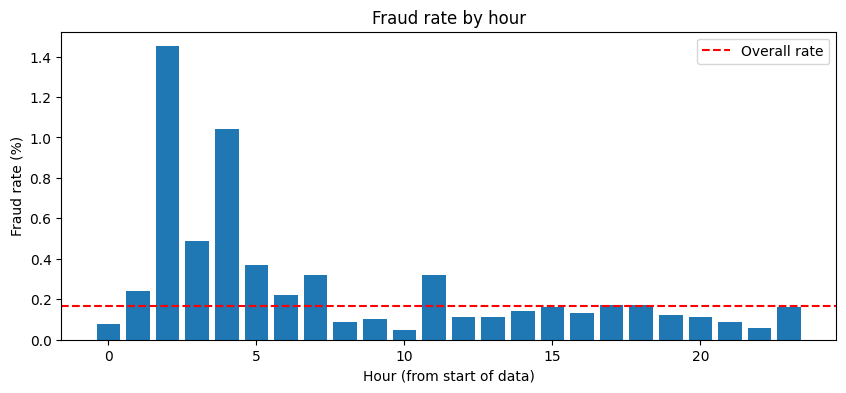

In [50]:
plt.figure(figsize=(10, 4))
plt.bar(hourly.index, hourly['fraud_pct'])
plt.axhline(df_clean['Class'].mean() * 100, color='red', linestyle='--', label='Overall rate')
plt.xlabel('Hour (from start of data)')
plt.ylabel('Fraud rate (%)')
plt.title('Fraud rate by hour')
plt.legend()
plt.show()

In [51]:
print(df_clean.groupby('Class')['Amount'].agg(['count', 'mean', 'median', 'max']).round(2))

        count    mean  median       max
Class                                  
0      283253   88.41   22.00  25691.16
1         473  123.87    9.82   2125.87


In [52]:
small = df_clean['Amount'] < 1

print(small.groupby(df_clean['Class']).sum())
print((small.groupby(df_clean['Class']).mean() * 100).round(2))

Class
0    16699
1       66
Name: Amount, dtype: int64
Class
0     5.90
1    13.95
Name: Amount, dtype: float64


In [53]:
print(df_clean.groupby('Class')['Amount'].describe(percentiles=[.1, .25, .5, .75, .9]).round(2))

          count    mean     std  min   10%   25%    50%     75%     90%  \
Class                                                                     
0      283253.0   88.41  250.38  0.0  1.00  5.67  22.00   77.46  203.00   
1         473.0  123.87  260.21  0.0  0.76  1.00   9.82  105.89  348.65   

            max  
Class            
0      25691.16  
1       2125.87  


### Insight: Amount, fraud vs normal
- Fraud median is 9.82 vs 22.00 for normal, and 13.95% of fraud rows are below 1 vs 5.90% of normal (about 2.4x).
- At the top end, the 90th percentile is 348.65 for fraud vs 203 for normal.
- So fraud amounts are more spread out: more very small amounts and also more large ones, compared with normal.
- Limitation: this describes the data only; it does not prove why fraudsters choose these amounts.

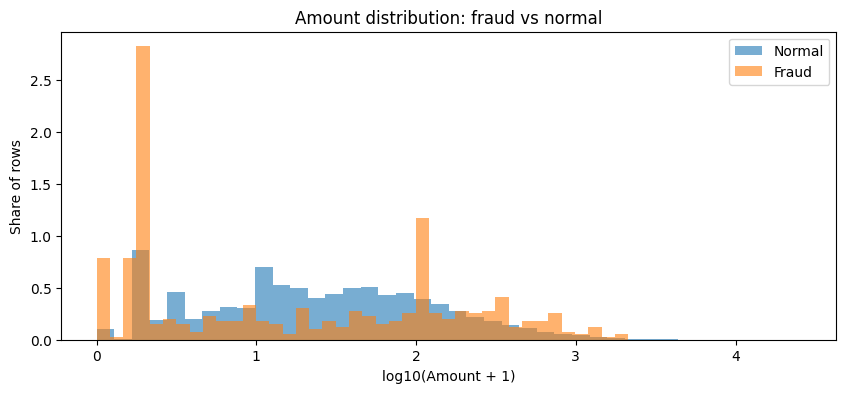

In [54]:
import numpy as np

normal_amt = np.log10(df_clean[df_clean['Class'] == 0]['Amount'] + 1)
fraud_amt = np.log10(df_clean[df_clean['Class'] == 1]['Amount'] + 1)

plt.figure(figsize=(10, 4))
plt.hist(normal_amt, bins=40, alpha=0.6, density=True, label='Normal')
plt.hist(fraud_amt, bins=40, alpha=0.6, density=True, label='Fraud')
plt.xlabel('log10(Amount + 1)')
plt.ylabel('Share of rows')
plt.title('Amount distribution: fraud vs normal')
plt.legend()
plt.show()

**Fraud is over-represented at both very small (below about 1) and large (above about 100) amounts, and under-represented in the middle.**

In [81]:
v_cols = [c for c in df_clean.columns if c.startswith('V')]

corr = df_clean[v_cols + ['Class']].corr()['Class'].drop('Class')
top = corr.abs().sort_values(ascending=False).head(5).index

print(corr[top].round(2))

V17   -0.31
V14   -0.29
V12   -0.25
V10   -0.21
V16   -0.19
Name: Class, dtype: float64


In [85]:
v_cols = df_clean.columns[1:29]
v_cols

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28'],
      dtype='object')

In [87]:
corr = df_clean.corr()
corr

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Hour
Time,1.000000,0.117927,-0.010556,-0.422054,-0.105845,0.173223,-0.063279,0.085335,-0.038203,-0.007861,...,0.143727,0.051474,-0.015954,-0.233262,-0.041818,-0.005171,-0.009305,-0.010559,-0.012359,0.415304
V1,0.117927,1.000000,0.006875,-0.008112,0.002257,-0.007036,0.000413,-0.009173,-0.001168,0.001828,...,-0.001436,-0.001330,-0.000723,-0.000222,-0.000684,-0.015706,-0.004861,-0.230105,-0.094486,-0.004949
V2,-0.010556,0.006875,1.000000,0.005278,-0.001495,0.005210,-0.000594,0.007425,0.002899,-0.000274,...,0.001237,-0.003855,0.000701,-0.001569,0.000253,0.007555,0.001611,-0.533428,0.084624,0.007929
V3,-0.422054,-0.008112,0.005278,1.000000,0.002829,-0.006879,-0.001511,-0.011721,-0.001815,-0.003579,...,-0.000275,0.000449,-0.000072,0.000425,-0.000094,-0.007051,-0.000134,-0.212410,-0.182322,-0.022645
V4,-0.105845,0.002257,-0.001495,0.002829,1.000000,0.001744,-0.000880,0.004657,0.000890,0.002154,...,0.000115,0.000732,-0.000120,0.000162,0.000777,0.001322,0.000231,0.099514,0.129326,-0.035251
V5,0.173223,-0.007036,0.005210,-0.006879,0.001744,1.000000,-0.000938,-0.008709,0.001430,-0.001213,...,-0.000559,0.001183,0.000198,0.000069,0.000390,-0.005798,-0.000820,-0.387685,-0.087812,-0.035817
V6,-0.063279,0.000413,-0.000594,-0.001511,-0.000880,-0.000938,1.000000,0.000436,0.003036,-0.000734,...,0.001104,-0.000755,0.001202,0.000697,-0.000028,0.000289,0.000925,0.216389,-0.043915,-0.019417
V7,0.085335,-0.009173,0.007425,-0.011721,0.004657,-0.008709,0.000436,1.000000,-0.006419,-0.004921,...,-0.002280,0.003303,-0.000384,-0.000072,0.000624,-0.004537,0.001657,0.400408,-0.172347,-0.010502
V8,-0.038203,-0.001168,0.002899,-0.001815,0.000890,0.001430,0.003036,-0.006419,1.000000,0.001038,...,-0.006156,0.004994,0.000113,0.000011,-0.001407,0.000613,-0.000099,-0.104662,0.033068,0.032706
V9,-0.007861,0.001828,-0.000274,-0.003579,0.002154,-0.001213,-0.000734,-0.004921,0.001038,1.000000,...,0.000785,0.000677,-0.000103,-0.000275,0.001253,0.008221,0.005591,-0.044123,-0.094021,-0.191132


In [88]:
print(corr.shape)

(32, 32)


In [96]:
corr_class = corr['Class']
corr_class

,Class
Time,-0.012359
V1,-0.094486
V2,0.084624
V3,-0.182322
V4,0.129326
V5,-0.087812
V6,-0.043915
V7,-0.172347
V8,0.033068
V9,-0.094021


In [97]:
corr_class.drop('Class')

,Class
Time,-0.012359
V1,-0.094486
V2,0.084624
V3,-0.182322
V4,0.129326
V5,-0.087812
V6,-0.043915
V7,-0.172347
V8,0.033068
V9,-0.094021


In [99]:
corr_class.drop('Class').abs().sort_values(ascending=False).head(5)

,Class
V17,0.313498
V14,0.293375
V12,0.250711
V10,0.206971
V16,0.187186


### Insight: V features
- V17, V14, V12, V10 and V16 have the strongest correlation with Class, all negative.
- This means these values tend to be lower in fraud rows than in normal rows.
- Limitation: V1 to V28 are anonymised, so we cannot explain them in business terms. Correlation shows association, not cause.

In [100]:
demo = pd.DataFrame({
    'attendance': [90, 80, 60, 40, 30],
    'tv_hours':   [1, 2, 3, 4, 5],
    'fail':       [0, 0, 0, 1, 1]
})
print(demo.corr().round(2))

            attendance  tv_hours  fail
attendance        1.00     -0.99 -0.90
tv_hours         -0.99      1.00  0.87
fail             -0.90      0.87  1.00


In [101]:
print(corr_class.round(2))
print(corr_class.drop('Class').abs().sort_values(ascending=False).head(5))

Time     -0.01
V1       -0.09
V2        0.08
V3       -0.18
V4        0.13
V5       -0.09
V6       -0.04
V7       -0.17
V8        0.03
V9       -0.09
V10      -0.21
V11       0.15
V12      -0.25
V13      -0.00
V14      -0.29
V15      -0.00
V16      -0.19
V17      -0.31
V18      -0.11
V19       0.03
V20       0.02
V21       0.03
V22       0.00
V23      -0.01
V24      -0.01
V25       0.00
V26       0.00
V27       0.02
V28       0.01
Amount    0.01
Class     1.00
Hour     -0.02
Name: Class, dtype: float64
V17    0.313498
V14    0.293375
V12    0.250711
V10    0.206971
V16    0.187186
Name: Class, dtype: float64


### Insight: V features and correlation
- V17 has the strongest correlation with Class (about -0.31), followed by V14, V12, V10 and V16, all negative. Fraud rows tend to have lower values in these columns.
- Amount (0.01) and Hour (-0.02) have almost no linear correlation with Class, yet Amount showed a clear U-shaped pattern in the histogram. Correlation only captures straight-line relationships.
- Limitation: V1 to V28 are anonymised, and correlation shows association, not cause.